# Used Car Price - Exploratory Data Analysis

Objectives :
- Search key factor for used car price
- Look for pattern and relation between car Price, Release Year, Kilometers count, Fuel Type and Model

Available informations :
- Car Name / Model
- Company / Brand
- Year of Manufacture
- Fuel Type
- Kilometers Driven
- Price

In [ ]:
import numpy as np
import pandas as pd
import polars as pl
import kagglehub
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# Load dataset
path = kagglehub.dataset_download("muhammadmusharraf444/used-car-price-prediction-dataset")

df = pl.read_csv(f"{path}/quikr_car.csv", infer_schema_length=1000, has_header=True)

print ("Overview")
df.head(n=10)

100%|██████████| 11.9k/11.9k [00:00<00:00, 26.2MB/s]

Extracting files...
Overview


name,company,year,Price,kms_driven,fuel_type
str,str,str,str,str,str
"""Hyundai Santro Xing XO eRLX Eu…","""Hyundai""","""2007""","""80,000""","""45,000 kms""","""Petrol"""
"""Mahindra Jeep CL550 MDI""","""Mahindra""","""2006""","""4,25,000""","""40 kms""","""Diesel"""
"""Maruti Suzuki Alto 800 Vxi""","""Maruti""","""2018""","""Ask For Price""","""22,000 kms""","""Petrol"""
"""Hyundai Grand i10 Magna 1.2 Ka…","""Hyundai""","""2014""","""3,25,000""","""28,000 kms""","""Petrol"""
"""Ford EcoSport Titanium 1.5L TD…","""Ford""","""2014""","""5,75,000""","""36,000 kms""","""Diesel"""
"""Ford EcoSport Titanium 1.5L TD…","""Ford""","""2015""","""Ask For Price""","""59,000 kms""","""Diesel"""
"""Ford Figo""","""Ford""","""2012""","""1,75,000""","""41,000 kms""","""Diesel"""
"""Hyundai Eon""","""Hyundai""","""2013""","""1,90,000""","""25,000 kms""","""Petrol"""
"""Ford EcoSport Ambiente 1.5L TD…","""Ford""","""2016""","""8,30,000""","""24,530 kms""","""Diesel"""


In [ ]:
# Count Duplicated rows
print (f"Duplicates : {df.is_duplicated().sum()}")

# Analyzing columns
df.describe()

Duplicates : 173


statistic,name,company,year,Price,kms_driven,fuel_type
str,str,str,str,str,str,str
"""count""","""892""","""892""","""892""","""892""","""840""","""837"""
"""null_count""","""0""","""0""","""0""","""0""","""52""","""55"""
"""mean""",null,null,null,null,null,null
"""std""",null,null,null,null,null,null
"""min""","""2012 Tata Sumo Gold f""","""2012""",""", Ac""","""1,00,000""","""0 kms""","""Diesel"""
"""25%""",null,null,null,null,null,null
"""50%""",null,null,null,null,null,null
"""75%""",null,null,null,null,null,null
"""max""","""very good condition tata bolts…","""very""","""zire""","""Ask For Price""","""Petrol""","""Petrol"""


Dataset is messy :
- Year contains invalid numerical (Ex: ",Ac", "zire")
- Price contains invalid numerical (Ex : "Ask For Price")
- Kms_driven contains invalid numerical (Ex : "Petrol")
- Kms_driven and fuel_type have missing values

In [ ]:
# Drop duplicates
df_clean = df.unique()

# Drop missing values
df_clean = df.drop_nulls()

# Cast year into Int64 (integer) and drop non numerical
df_clean = df_clean.with_columns(pl.col('year').cast(pl.Int64, strict=False)).drop_nulls()

# Clean Prices (get rid of ",") and cast into Int64 (integer), drop non numerical after
df_clean = df_clean.with_columns(pl.col('Price').str.replace_all(',', '').cast(pl.Int64, strict=False)).drop_nulls()

# Clean Kms_driven (get rid of "Kms") and cast into Int64 (integer), drop non numerical after
df_clean = df_clean.with_columns(pl.col('kms_driven').str.replace_all(',', '').str.extract(r"(\d+)").cast(pl.Int64, strict=False)).drop_nulls()

df_clean.describe()


statistic,name,company,year,Price,kms_driven,fuel_type
str,str,str,f64,f64,f64,str
"""count""","""816""","""816""",816.0,816.0,816.0,"""816"""
"""null_count""","""0""","""0""",0.0,0.0,0.0,"""0"""
"""mean""",null,null,2012.444853,411717.615196,46275.531863,null
"""std""",null,null,4.002992,475184.422264,34297.428044,null
"""min""","""Audi A3 Cabriolet 40 TFSI""","""Audi""",1995.0,30000.0,0.0,"""Diesel"""
"""25%""",null,null,2010.0,175000.0,27000.0,null
"""50%""",null,null,2013.0,299999.0,41000.0,null
"""75%""",null,null,2015.0,490000.0,56758.0,null
"""max""","""Volvo S80 Summum D4""","""Volvo""",2019.0,8.500003e6,400000.0,"""Petrol"""


# Analysis

## Numerical feature relationship

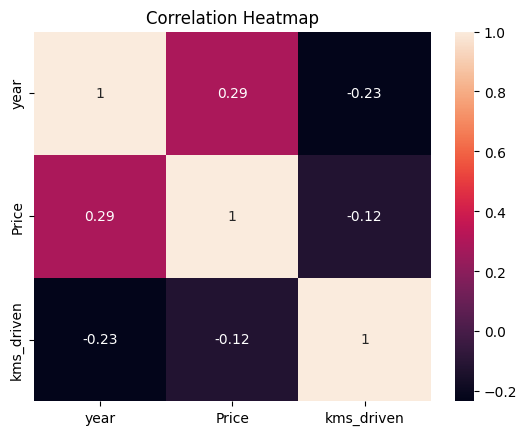

In [ ]:
numerical_only = df_clean.select(['year', 'Price', 'kms_driven'])

ax = sns.heatmap(numerical_only.corr(), annot=True)

ax.set_xticklabels(numerical_only.columns)
ax.set_yticklabels(numerical_only.columns)

plt.title("Correlation Heatmap")

plt.show()

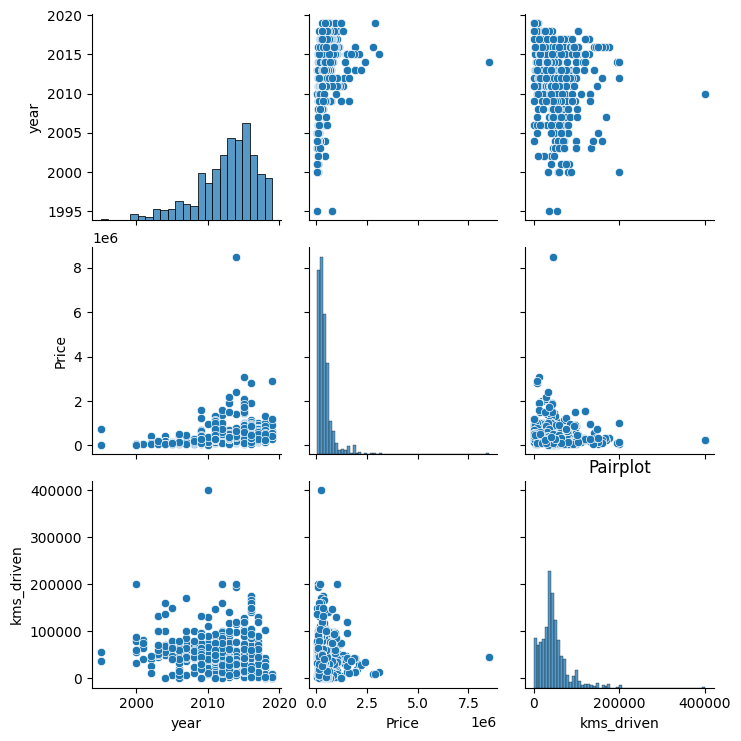

In [ ]:
sns.pairplot(df_clean.to_pandas())

plt.title("Pairplot")

plt.show()

## Distribution of categorical feature : Company, Fuel type

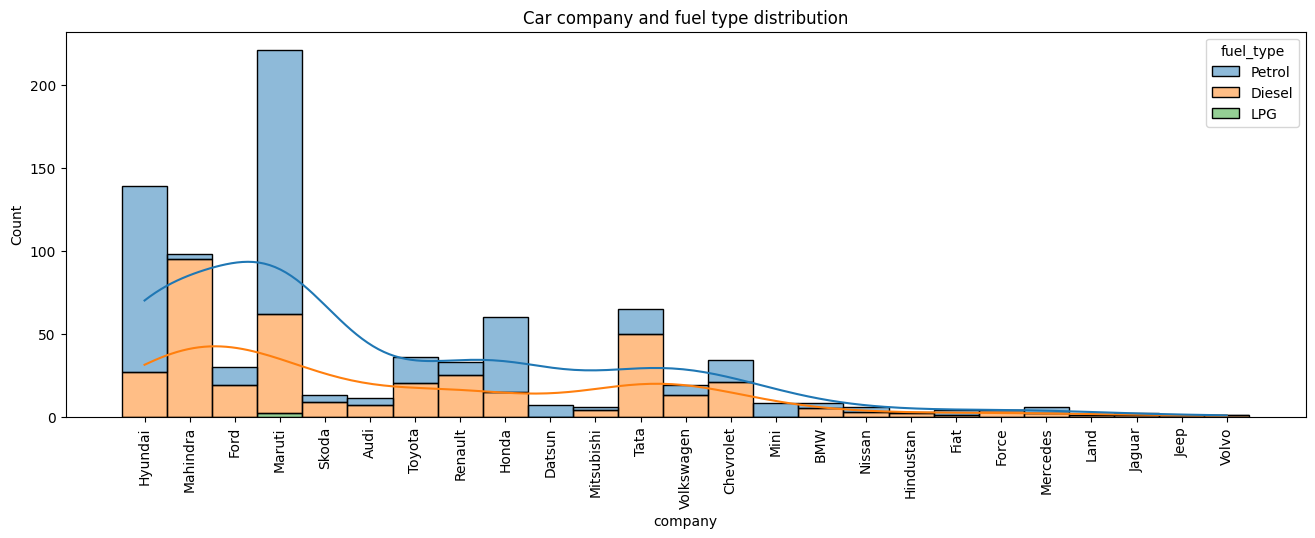

In [ ]:
plt.figure(figsize=(16, 5))

sns.histplot(df_clean.to_pandas(), x='company', hue='fuel_type', multiple='stack', kde=True)

plt.xticks(rotation=90)

plt.title("Car company and fuel type distribution")

plt.show()

## Insights
1.  **Numerical Feature Relationships**:
    *   **Price vs. Year**: There appears to be a little positive correlation, where newer cars generally command higher prices.
    *   **Price vs. Kilometers Driven**: A weak inverse relationship is observed
    *   **Year vs. Kilometers Driven**: An inverse relationship is observed.
2.  **Categorical Feature Distributions**:
    *   **Company**: Maruti, Hyundai, Mahindra and Tata are the most frequently represented car companies in the dataset.

# Conclusion

We can see some **relations** between features in the dataset. but overall the correlation is not strong enough.  
`
A model trained on the **available features** alone won't perform well enough.

# Machine Learning : Prediksi Harga Mobil Bekas dengan Decision Tree

Pada bagian ini kita membangun model **Decision Tree Regressor** untuk memprediksi harga mobil bekas, lalu membuat program interaktif: user memasukkan data mobil, program mengeluarkan **prediksi harga** berdasarkan pola pada dataset.

Kolom pada dataset (`quikr_car.csv`) :
- `name` : nama lengkap mobil
- `company` : merk
- `year` : tahun pembuatan
- `Price` : harga (target yang diprediksi, dalam Rupee India)
- `kms_driven` : jarak tempuh
- `fuel_type` : jenis bahan bakar

Alur : *Persiapan data → Split train/test → Training + tuning → Evaluasi → Prediksi dari input user*

## 1. Persiapan Data untuk Model

Data dibersihkan ulang dari `df` (data mentah) supaya bagian ML berdiri sendiri. Beberapa catatan :
- `Price` dan `kms_driven` mengandung koma dan teks ("Ask For Price", "kms"), jadi harus dibersihkan lalu dijadikan angka. Angka dengan koma seperti `45,000 kms` dibaca utuh sebagai **45000**.
- Nama mobil terlalu spesifik (525 nama unik), jadi dibuat fitur **`model`** dari 3 kata pertama nama mobil (contoh : `Maruti Suzuki Alto`). Ini menggabungkan varian yang mirip.
- **Outlier** harga (di atas batas IQR) dan jarak tempuh ekstrem (> 200.000 km) dibuang supaya pohon tidak terdistorsi mobil super mahal yang jumlahnya sangat sedikit.

In [ ]:
raw = df.to_pandas()

data = raw.copy()
data['year'] = pd.to_numeric(data['year'], errors='coerce')
data['Price'] = pd.to_numeric(data['Price'].str.replace(',', '', regex=False), errors='coerce')
data['kms'] = pd.to_numeric(
    data['kms_driven'].str.replace(',', '', regex=False).str.extract(r'(\d+)')[0],
    errors='coerce'
)

# Buang data kosong / tidak valid & duplikat
data = data.dropna(subset=['name', 'company', 'year', 'Price', 'kms', 'fuel_type']).drop_duplicates()

# Fitur model = 3 kata pertama nama mobil
data['model'] = data['name'].str.split().str[:3].str.join(' ')

# Buang outlier harga (IQR) dan kms ekstrem
q1, q3 = data['Price'].quantile([0.25, 0.75])
batas_atas = q3 + 1.5 * (q3 - q1)
data = data[(data['Price'] <= batas_atas) & (data['kms'] <= 200_000)].reset_index(drop=True)

FITUR_KATEGORI = ['company', 'model', 'fuel_type']
FITUR_ANGKA = ['year', 'kms']
TARGET = 'Price'

print(f"Jumlah data siap dipakai : {len(data)} baris (batas harga atas : {batas_atas:,.0f})")
data[FITUR_KATEGORI + FITUR_ANGKA + [TARGET]].head(10)

Jumlah data siap dipakai : 678 baris (batas harga atas : 977,498)


,company,model,fuel_type,year,kms,Price
0,Hyundai,Hyundai Santro Xing,Petrol,2007.0,45000.0,80000.0
1,Mahindra,Mahindra Jeep CL550,Diesel,2006.0,40.0,425000.0
2,Hyundai,Hyundai Grand i10,Petrol,2014.0,28000.0,325000.0
3,Ford,Ford EcoSport Titanium,Diesel,2014.0,36000.0,575000.0
4,Ford,Ford Figo,Diesel,2012.0,41000.0,175000.0
5,Hyundai,Hyundai Eon,Petrol,2013.0,25000.0,190000.0
6,Ford,Ford EcoSport Ambiente,Diesel,2016.0,24530.0,830000.0
7,Maruti,Maruti Suzuki Alto,Petrol,2015.0,60000.0,250000.0
8,Skoda,Skoda Fabia Classic,Petrol,2010.0,60000.0,182000.0
9,Maruti,Maruti Suzuki Stingray,Petrol,2015.0,30000.0,315000.0


## 2. Split Data & Training Model

Data dibagi **80% training** dan **20% testing**. Fitur kategori (`company`, `model`, `fuel_type`) diubah dengan *One-Hot Encoding*, lalu `GridSearchCV` mencari kedalaman pohon (`max_depth`) dan `min_samples_leaf` terbaik dengan cross-validation 5 lipatan (kriteria : MAE terkecil).

In [ ]:
X = data[FITUR_KATEGORI + FITUR_ANGKA]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocess = ColumnTransformer(
    [('kategori', OneHotEncoder(handle_unknown='ignore'), FITUR_KATEGORI)],
    remainder='passthrough'   # year & kms tetap angka
)

pipeline = Pipeline([
    ('preprocess', preprocess),
    ('tree', DecisionTreeRegressor(random_state=42))
])

param_grid = {
    'tree__max_depth': [6, 8, 10, 12, None],
    'tree__min_samples_leaf': [2, 3, 5, 10],
}

grid = GridSearchCV(pipeline, param_grid, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
grid.fit(X_train, y_train)

model_dt = grid.best_estimator_
print("Parameter terbaik :", grid.best_params_)

Parameter terbaik : {'tree__max_depth': 10, 'tree__min_samples_leaf': 2}


## 3. Evaluasi Model

MAE  (rata-rata selisih absolut) : 103,249
RMSE                             : 144,660
R2 Score                         : 0.466


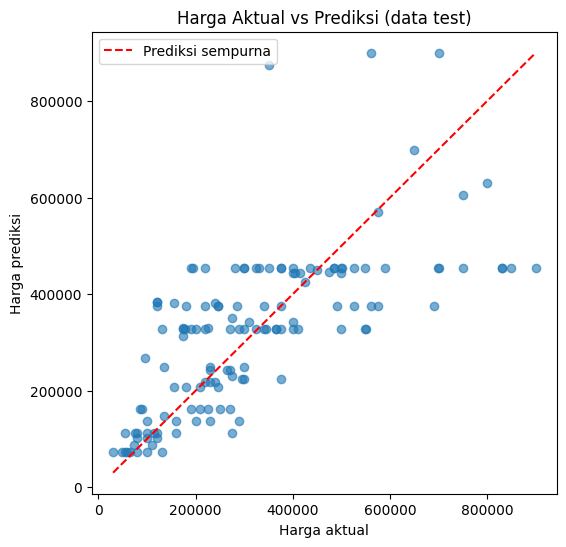

In [ ]:
import matplotlib.pyplot as plt

pred_test = model_dt.predict(X_test)

mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))
r2 = r2_score(y_test, pred_test)

print(f"MAE  (rata-rata selisih absolut) : {mae:,.0f}")
print(f"RMSE                             : {rmse:,.0f}")
print(f"R2 Score                         : {r2:.3f}")

# Harga aktual vs prediksi
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_test, alpha=0.6)
batas = [y_test.min(), y_test.max()]
plt.plot(batas, batas, 'r--', label='Prediksi sempurna')
plt.xlabel('Harga aktual')
plt.ylabel('Harga prediksi')
plt.title('Harga Aktual vs Prediksi (data test)')
plt.legend()
plt.show()

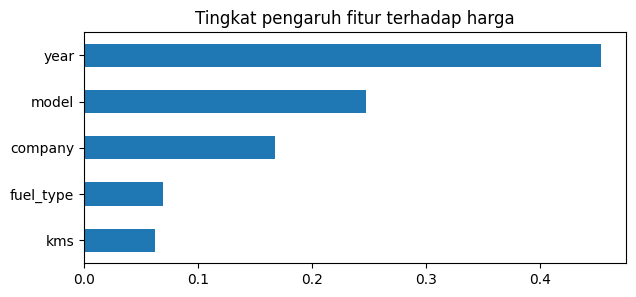

In [ ]:
# Fitur yang paling berpengaruh pada keputusan pohon
nama_fitur = model_dt.named_steps['preprocess'].get_feature_names_out()
pentingnya = pd.Series(model_dt.named_steps['tree'].feature_importances_, index=nama_fitur)

# Gabungkan hasil One-Hot (mis. company_Hyundai) kembali per kolom asal
def kolom_asal(n):
    n = n.replace('kategori__', '').replace('remainder__', '')
    for k in FITUR_KATEGORI:
        if n.startswith(k + '_'):
            return k
    return n

per_kolom = pentingnya.groupby(kolom_asal).sum().sort_values()

per_kolom.plot(kind='barh', figsize=(7, 3), title='Tingkat pengaruh fitur terhadap harga')
plt.show()

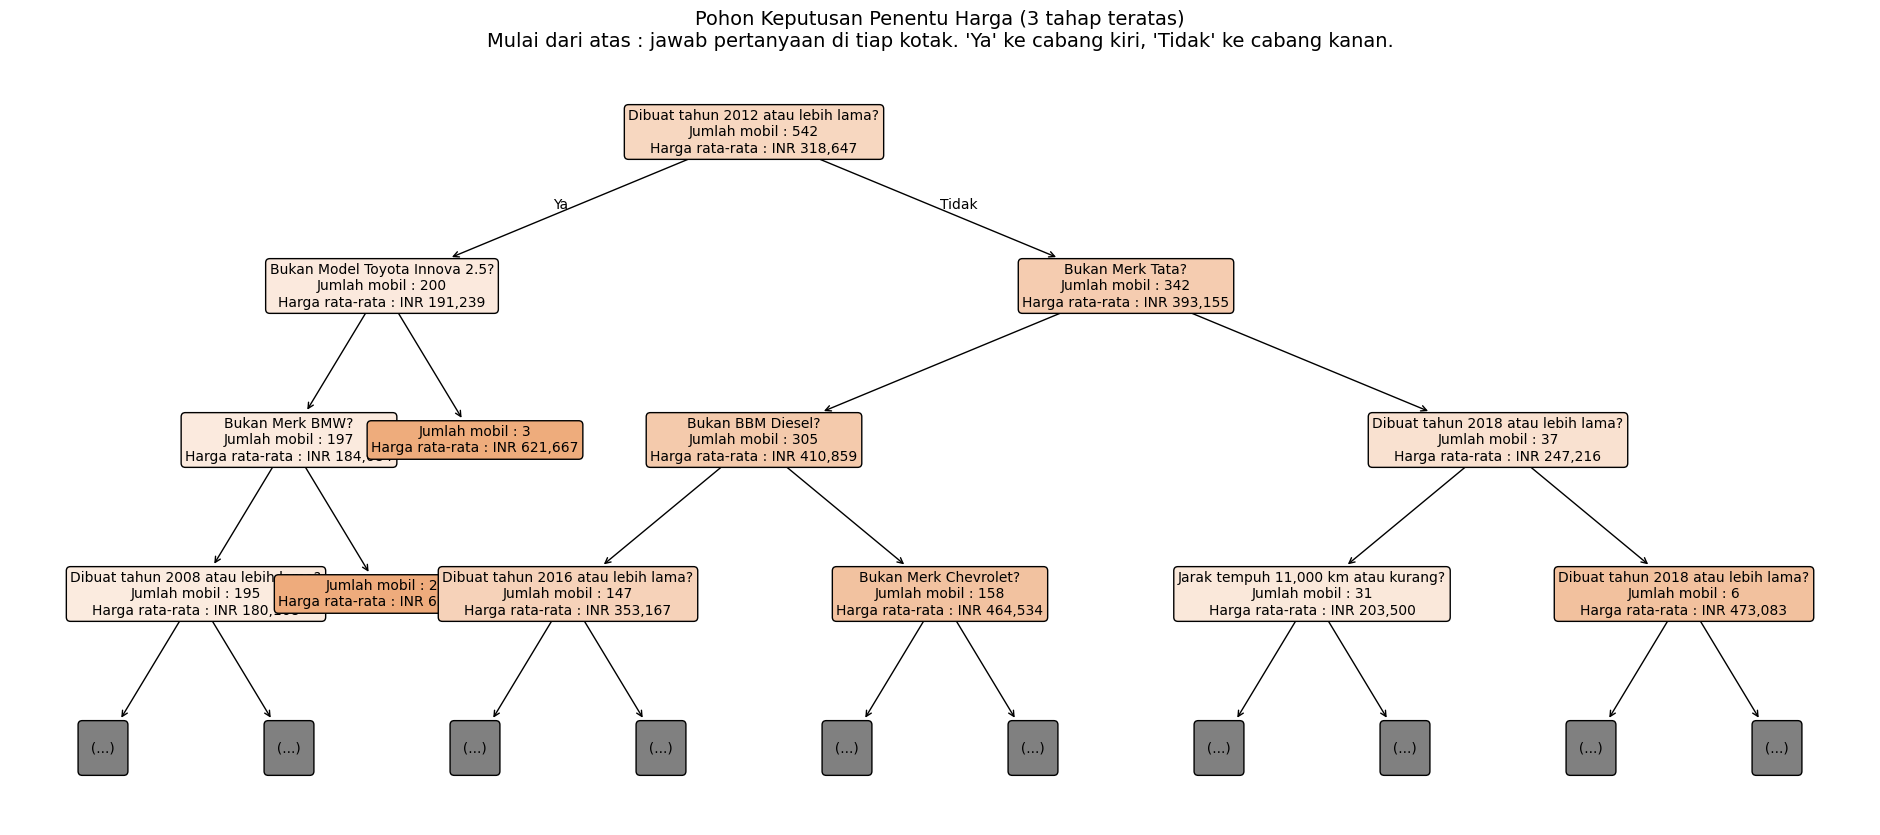

In [ ]:
import re

# Ubah nama fitur teknis jadi bahasa sehari-hari (mis. "kategori__company_Hyundai" -> "Merk Hyundai")
def nama_manusiawi(n):
    n = n.replace('kategori__', '').replace('remainder__', '')
    if n == 'year':
        return 'Tahun'
    if n == 'kms':
        return 'Jarak tempuh (km)'
    if n.startswith('company_'):
        return 'Merk ' + n[len('company_'):]
    if n.startswith('model_'):
        return 'Model ' + n[len('model_'):]
    if n.startswith('fuel_type_'):
        return 'BBM ' + n[len('fuel_type_'):]
    return n

nama_fitur_rapi = [nama_manusiawi(n) for n in nama_fitur]

plt.figure(figsize=(24, 10))
kotak = plot_tree(
    model_dt.named_steps['tree'],
    feature_names=nama_fitur_rapi,
    max_depth=3,
    impurity=False,     # sembunyikan istilah teknis "squared_error"
    filled=True,
    rounded=True,
    fontsize=10
)

# Terjemahkan teks bawaan sklearn jadi kalimat yang mudah dibaca
def rapikan(teks):
    if teks == 'True':
        return 'Ya'
    if teks == 'False':
        return 'Tidak'

    baris_baru = []
    for baris in teks.split('\n'):
        kondisi = re.match(r'(.+?) <= ([\d.]+)', baris)
        if kondisi:
            nama, batas = kondisi.group(1), float(kondisi.group(2))
            if nama.startswith(('Merk ', 'Model ', 'BBM ')):
                baris = f"Bukan {nama}?"                 # hasil One-Hot : 0 = bukan kategori itu
            elif nama == 'Tahun':
                baris = f"Dibuat tahun {batas:.0f} atau lebih lama?"
            else:
                baris = f"Jarak tempuh {batas:,.0f} km atau kurang?"
        elif baris.startswith('samples'):
            baris = f"Jumlah mobil : {int(float(baris.split('=')[1]))}"
        elif baris.startswith('value'):
            baris = f"Harga rata-rata : INR {float(baris.split('=')[1]):,.0f}"
        baris_baru.append(baris)
    return '\n'.join(baris_baru)

for kotak_teks in kotak:
    kotak_teks.set_text(rapikan(kotak_teks.get_text()))

# Label cabang "True"/"False" di atas panah juga diganti
for teks in plt.gca().texts:
    isi = teks.get_text().strip()
    if isi in ('True', 'False'):
        teks.set_text(rapikan(isi))

plt.title("Pohon Keputusan Penentu Harga (3 tahap teratas)\n"
          "Mulai dari atas : jawab pertanyaan di tiap kotak. 'Ya' ke cabang kiri, 'Tidak' ke cabang kanan.",
          fontsize=14)
plt.show()

## 4. Prediksi Harga dari Input User

Jalankan sel di bawah, lalu isi data mobil yang diminta. Program akan menampilkan **estimasi harga** beserta **rentang harga mobil serupa** di dataset (data training yang jatuh pada daun pohon yang sama dengan mobil Anda).

Catatan :
- Harga pada dataset adalah **Rupee India (INR)**. Konversi ke Rupiah bersifat perkiraan, ubah `KURS_INR_KE_IDR` sesuai kurs terbaru.
- Jika model mobil yang diketik tidak ada di dataset, prediksi hanya memakai merk, tahun, jarak tempuh, dan bahan bakar sehingga akurasinya lebih rendah.

In [ ]:
KURS_INR_KE_IDR = 195   # perkiraan, sesuaikan dengan kurs terbaru

daftar_merk = sorted(data['company'].unique())
daftar_bbm = sorted(data['fuel_type'].unique())
tahun_min, tahun_max = int(data['year'].min()), int(data['year'].max())


def input_angka(pesan, minimum, maksimum):
    while True:
        try:
            nilai = int(input(pesan).replace(',', '').replace('.', '').strip())
            if minimum <= nilai <= maksimum:
                return nilai
            print(f"  Masukkan angka antara {minimum} dan {maksimum}.")
        except ValueError:
            print("  Input harus berupa angka.")


def input_pilihan(pesan, pilihan):
    peta = {p.lower(): p for p in pilihan}
    while True:
        jawab = input(pesan).strip().lower()
        if jawab in peta:
            return peta[jawab]
        print("  Pilihan tidak ditemukan, coba lagi.")


def prediksi_harga(merk, nama_mobil, tahun, kms, bbm):
    model_mobil = ' '.join(nama_mobil.split()[:3])
    baris = pd.DataFrame([{
        'company': merk, 'model': model_mobil, 'fuel_type': bbm,
        'year': tahun, 'kms': kms
    }])
    harga = model_dt.predict(baris)[0]

    # Rentang harga data training pada daun yang sama
    pre = model_dt.named_steps['preprocess']
    pohon = model_dt.named_steps['tree']
    daun_input = pohon.apply(pre.transform(baris))[0]
    daun_train = pohon.apply(pre.transform(X_train))
    harga_mirip = y_train[daun_train == daun_input]

    return harga, harga_mirip, model_mobil in set(data['model'])


def jalankan_program():
    print("=" * 55)
    print("   PREDIKSI HARGA MOBIL BEKAS (Decision Tree)")
    print("=" * 55)
    print("Merk tersedia :", ', '.join(daftar_merk))
    merk = input_pilihan("Merk mobil              : ", daftar_merk)

    contoh = data.loc[data['company'] == merk, 'model'].value_counts().head(8).index.tolist()
    print("Contoh model di dataset :", ', '.join(contoh))
    nama = input(f"Nama/model mobil (mis. {contoh[0]}) : ").strip()
    if not nama.lower().startswith(merk.lower()):
        nama = f"{merk} {nama}"   # lengkapi dengan merk agar sama dengan format dataset

    tahun = input_angka(f"Tahun pembuatan ({tahun_min}-{tahun_max}) : ", tahun_min, tahun_max)
    kms = input_angka("Jarak tempuh (km)         : ", 0, 1_000_000)
    print("Bahan bakar tersedia :", ', '.join(daftar_bbm))
    bbm = input_pilihan("Jenis bahan bakar        : ", daftar_bbm)

    harga, mirip, model_dikenal = prediksi_harga(merk, nama, tahun, kms, bbm)

    print("\n" + "-" * 55)
    print(f"Mobil   : {nama} | {tahun} | {kms:,} km | {bbm}")
    print(f"Prediksi harga : Rp {harga * KURS_INR_KE_IDR:,.0f}  (INR {harga:,.0f})")
    if len(mirip) > 1:
        print(f"Rentang mobil serupa di dataset : INR {mirip.min():,.0f} - {mirip.max():,.0f} "
              f"({len(mirip)} data)")
    if not model_dikenal:
        print("Catatan : model mobil ini tidak ada di dataset, prediksi kurang akurat.")
    print("-" * 55)


jalankan_program()

   PREDIKSI HARGA MOBIL BEKAS (Decision Tree)
Merk tersedia : Audi, BMW, Chevrolet, Datsun, Fiat, Force, Ford, Hindustan, Honda, Hyundai, Jeep, Mahindra, Maruti, Mercedes, Mitsubishi, Nissan, Renault, Skoda, Tata, Toyota, Volkswagen
Merk mobil              : Maruti
Contoh model di dataset : Maruti Suzuki Swift, Maruti Suzuki Alto, Maruti Suzuki Wagon, Maruti Suzuki Ertiga, Maruti Suzuki Dzire, Maruti Suzuki Zen, Maruti Suzuki Omni, Maruti Suzuki Ritz
Nama/model mobil (mis. Maruti Suzuki Swift) : Maruti Suzuki Alto
Tahun pembuatan (1995-2019) : 2015
Jarak tempuh (km)         : 38000
Bahan bakar tersedia : Diesel, LPG, Petrol
Jenis bahan bakar        : Petrol

-------------------------------------------------------
Mobil   : Maruti Suzuki Alto | 2015 | 38,000 km | Petrol
Prediksi harga : Rp 37,635,000  (INR 193,000)
Rentang mobil serupa di dataset : INR 160,000 - 220,000 (3 data)
-------------------------------------------------------


## Kesimpulan Model

- Model Decision Tree dengan data yang sudah dibersihkan (outlier dibuang, fitur `model` ditambahkan) menghasilkan R2 yang cukup rendah pada data test (lihat hasil evaluasi di atas, kira-kira 0.4 - 0.5 dan bisa berubah tergantung pembagian data). Ini sesuai kesimpulan EDA : data ini terbatas (tidak ada fitur seperti kondisi mobil, tipe transmisi, atau kapasitas mesin).
- Hasil prediksi sebaiknya dipakai sebagai **perkiraan awal**, bukan harga pasti.
- Untuk memperbaiki : kumpulkan data lebih banyak, atau coba Random Forest / Gradient Boosting yang biasanya lebih stabil daripada satu pohon.

In [ ]:

# Prediksi pada data training dan testing
pred_train = model_dt.predict(X_train)
pred_test = model_dt.predict(X_test)

# Evaluasi R2
r2_train = r2_score(y_train, pred_train)
r2_test = r2_score(y_test, pred_test)

# Evaluasi MAE
mae_train = mean_absolute_error(y_train, pred_train)
mae_test = mean_absolute_error(y_test, pred_test)

print("=== PERBANDINGAN TRAINING VS TESTING ===")
print(f"R2 Training : {r2_train:.3f}")
print(f"R2 Testing  : {r2_test:.3f}")
print(f"MAE Training: {mae_train:,.0f}")
print(f"MAE Testing : {mae_test:,.0f}")

print("\n=== ANALISIS ===")
selisih = r2_train - r2_test

if selisih > 0.2:
    print("Indikasi overfitting cukup kuat.")
elif selisih > 0.1:
    print("Ada indikasi overfitting.")
else:
    print("Tidak terlihat indikasi overfitting yang besar.")


=== PERBANDINGAN TRAINING VS TESTING ===
R2 Training : 0.738
R2 Testing  : 0.466
MAE Training: 72,375
MAE Testing : 103,249

=== ANALISIS ===
Indikasi overfitting cukup kuat.


# Machine Learning : Prediksi Harga Mobil Bekas dengan Random Forest

Pada bagian ini kita membangun model **Random Forest Regressor** untuk memprediksi harga mobil bekas, lalu membuat program interaktif: user memasukkan data mobil, program mengeluarkan **prediksi harga** berdasarkan pola pada dataset.

Bagian ini **berdiri sendiri** : prosesnya dimulai dari data mentah `df` (hasil load dataset di atas), tanpa memakai variabel dari bagian EDA maupun Decision Tree.

Random Forest adalah kumpulan banyak pohon keputusan. Tiap pohon dilatih pada sampel data dan subset fitur yang berbeda, lalu hasil prediksinya **dirata-rata**. Dengan cara ini model tidak terlalu bergantung pada satu pohon sehingga biasanya lebih stabil dibanding satu Decision Tree.

Kolom pada dataset (`quikr_car.csv`) :
- `name` : nama lengkap mobil
- `company` : merk
- `year` : tahun pembuatan
- `Price` : harga (target yang diprediksi, dalam Rupee India)
- `kms_driven` : jarak tempuh
- `fuel_type` : jenis bahan bakar

Alur : *Persiapan data → Split train/test → Training + tuning → Evaluasi → Fitur berpengaruh → Prediksi dari input user*

## 1. Persiapan Data untuk Model

Data dibersihkan dari `df` (data mentah). Langkahnya :
- `year`, `Price`, dan `kms_driven` masih berupa teks (ada koma, "kms", "Ask For Price", dan nilai tidak valid), jadi dibersihkan lalu dijadikan angka. Angka dengan koma seperti `45,000 kms` dibaca utuh sebagai **45000**.
- Baris dengan nilai kosong, tidak valid, atau duplikat dibuang.
- Nama mobil terlalu spesifik, jadi dibuat fitur **`model`** dari 3 kata pertama nama mobil (contoh : `Maruti Suzuki Alto`). Ini menggabungkan varian yang mirip.
- **Outlier** harga (di atas batas IQR) dan jarak tempuh ekstrem (> 200.000 km) dibuang.

In [ ]:
import re
from sklearn.ensemble import RandomForestRegressor

# Langkah 1 : ubah data mentah menjadi angka
data_rf = df.to_pandas().copy()
print(f"Data mentah                      : {len(data_rf)} baris")

data_rf['year'] = pd.to_numeric(data_rf['year'], errors='coerce')
data_rf['Price'] = pd.to_numeric(data_rf['Price'].str.replace(',', '', regex=False), errors='coerce')
data_rf['kms'] = pd.to_numeric(
    data_rf['kms_driven'].str.replace(',', '', regex=False).str.extract(r'(\d+)')[0],
    errors='coerce'
)

# Langkah 2 : buang data kosong / tidak valid dan duplikat
data_rf = data_rf.dropna(subset=['name', 'company', 'year', 'Price', 'kms', 'fuel_type'])
print(f"Setelah buang kosong/tidak valid : {len(data_rf)} baris")

data_rf = data_rf.drop_duplicates()
print(f"Setelah buang duplikat           : {len(data_rf)} baris")

data_rf[['name', 'company', 'year', 'Price', 'kms', 'fuel_type']].head(10)

Data mentah                      : 892 baris
Setelah buang kosong/tidak valid : 816 baris
Setelah buang duplikat           : 724 baris


,name,company,year,Price,kms,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007.0,80000.0,45000.0,Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006.0,425000.0,40.0,Diesel
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014.0,325000.0,28000.0,Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014.0,575000.0,36000.0,Diesel
6,Ford Figo,Ford,2012.0,175000.0,41000.0,Diesel
7,Hyundai Eon,Hyundai,2013.0,190000.0,25000.0,Petrol
8,Ford EcoSport Ambiente 1.5L TDCi,Ford,2016.0,830000.0,24530.0,Diesel
9,Maruti Suzuki Alto K10 VXi AMT,Maruti,2015.0,250000.0,60000.0,Petrol
10,Skoda Fabia Classic 1.2 MPI,Skoda,2010.0,182000.0,60000.0,Petrol
11,Maruti Suzuki Stingray VXi,Maruti,2015.0,315000.0,30000.0,Petrol


In [ ]:
# Langkah 3 : fitur model = 3 kata pertama nama mobil
data_rf['model'] = data_rf['name'].str.split().str[:3].str.join(' ')
print(f"Jumlah nama unik : {data_rf['name'].nunique()}  ->  jumlah model unik : {data_rf['model'].nunique()}")

# Langkah 4 : buang outlier harga (IQR) dan kms ekstrem
q1, q3 = data_rf['Price'].quantile([0.25, 0.75])
batas_atas_rf = q3 + 1.5 * (q3 - q1)
sebelum = len(data_rf)
data_rf = data_rf[(data_rf['Price'] <= batas_atas_rf) & (data_rf['kms'] <= 200_000)].reset_index(drop=True)

FITUR_KATEGORI_RF = ['company', 'model', 'fuel_type']
FITUR_ANGKA_RF = ['year', 'kms']
TARGET_RF = 'Price'

print(f"Outlier dibuang  : {sebelum - len(data_rf)} baris (batas harga atas : {batas_atas_rf:,.0f})")
print(f"Jumlah data siap dipakai : {len(data_rf)} baris")
data_rf[FITUR_KATEGORI_RF + FITUR_ANGKA_RF + [TARGET_RF]].head(10)

Jumlah nama unik : 463  ->  jumlah model unik : 254
Outlier dibuang  : 46 baris (batas harga atas : 977,498)
Jumlah data siap dipakai : 678 baris


,company,model,fuel_type,year,kms,Price
0,Hyundai,Hyundai Santro Xing,Petrol,2007.0,45000.0,80000.0
1,Mahindra,Mahindra Jeep CL550,Diesel,2006.0,40.0,425000.0
2,Hyundai,Hyundai Grand i10,Petrol,2014.0,28000.0,325000.0
3,Ford,Ford EcoSport Titanium,Diesel,2014.0,36000.0,575000.0
4,Ford,Ford Figo,Diesel,2012.0,41000.0,175000.0
5,Hyundai,Hyundai Eon,Petrol,2013.0,25000.0,190000.0
6,Ford,Ford EcoSport Ambiente,Diesel,2016.0,24530.0,830000.0
7,Maruti,Maruti Suzuki Alto,Petrol,2015.0,60000.0,250000.0
8,Skoda,Skoda Fabia Classic,Petrol,2010.0,60000.0,182000.0
9,Maruti,Maruti Suzuki Stingray,Petrol,2015.0,30000.0,315000.0


## 2. Split Data & Training Model

Data dibagi **80% training** dan **20% testing**. Fitur kategori (`company`, `model`, `fuel_type`) diubah dengan *One-Hot Encoding*, lalu `GridSearchCV` mencari kombinasi terbaik dari :
- `n_estimators` : jumlah pohon dalam hutan
- `max_depth` : kedalaman maksimum tiap pohon
- `min_samples_leaf` : jumlah data minimum di setiap daun
- `max_features` : porsi fitur yang dicoba pada setiap pemisahan

Pencarian memakai cross-validation 5 lipatan (kriteria : MAE terkecil).

In [ ]:
X_rf = data_rf[FITUR_KATEGORI_RF + FITUR_ANGKA_RF]
y_rf = data_rf[TARGET_RF]

X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(X_rf, y_rf, test_size=0.2, random_state=42)

print(f"Data training : {len(X_train_rf)} baris")
print(f"Data testing  : {len(X_test_rf)} baris")

Data training : 542 baris
Data testing  : 136 baris


In [ ]:
preprocess_rf = ColumnTransformer(
    [('kategori', OneHotEncoder(handle_unknown='ignore'), FITUR_KATEGORI_RF)],
    remainder='passthrough'   # year & kms tetap angka
)

pipeline_rf = Pipeline([
    ('preprocess', preprocess_rf),
    ('forest', RandomForestRegressor(random_state=42, n_jobs=-1))
])

param_grid_rf = {
    'forest__n_estimators': [100, 300],
    'forest__max_depth': [10, None],
    'forest__min_samples_leaf': [1, 2, 3],
    'forest__max_features': [0.3, 0.5, 1.0],
}

grid_rf = GridSearchCV(pipeline_rf, param_grid_rf, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_rf.fit(X_train_rf, y_train_rf)

model_rf = grid_rf.best_estimator_
print("Parameter terbaik :", grid_rf.best_params_)

Parameter terbaik : {'forest__max_depth': None, 'forest__max_features': 0.3, 'forest__min_samples_leaf': 1, 'forest__n_estimators': 300}


## 3. Evaluasi Model

MAE  (rata-rata selisih absolut) : 75,491
RMSE                             : 112,209
R2 Score                         : 0.679


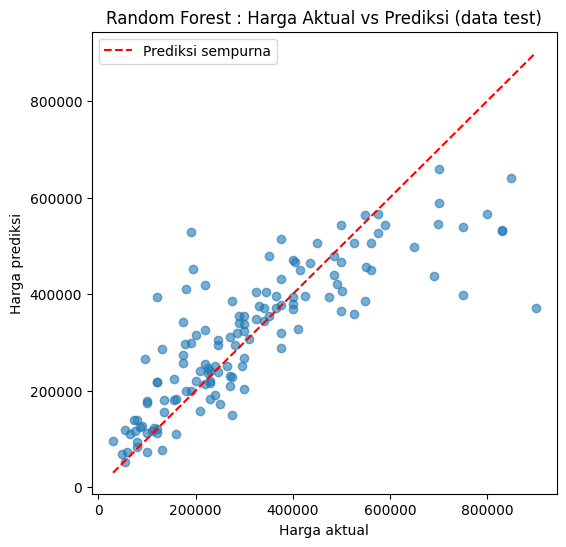

In [ ]:
pred_test_rf = model_rf.predict(X_test_rf)

mae_rf = mean_absolute_error(y_test_rf, pred_test_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test_rf, pred_test_rf))
r2_rf = r2_score(y_test_rf, pred_test_rf)

print(f"MAE  (rata-rata selisih absolut) : {mae_rf:,.0f}")
print(f"RMSE                             : {rmse_rf:,.0f}")
print(f"R2 Score                         : {r2_rf:.3f}")

# Harga aktual vs prediksi
plt.figure(figsize=(6, 6))
plt.scatter(y_test_rf, pred_test_rf, alpha=0.6)
batas = [y_test_rf.min(), y_test_rf.max()]
plt.plot(batas, batas, 'r--', label='Prediksi sempurna')
plt.xlabel('Harga aktual')
plt.ylabel('Harga prediksi')
plt.title('Random Forest : Harga Aktual vs Prediksi (data test)')
plt.legend()
plt.show()

In [ ]:
# Perbandingan performa pada data training vs testing
pred_train_rf = model_rf.predict(X_train_rf)

r2_train_rf = r2_score(y_train_rf, pred_train_rf)
r2_test_rf = r2_score(y_test_rf, pred_test_rf)
mae_train_rf = mean_absolute_error(y_train_rf, pred_train_rf)
mae_test_rf = mean_absolute_error(y_test_rf, pred_test_rf)

print("=== PERBANDINGAN TRAINING VS TESTING ===")
print(f"R2 Training : {r2_train_rf:.3f}")
print(f"R2 Testing  : {r2_test_rf:.3f}")
print(f"MAE Training: {mae_train_rf:,.0f}")
print(f"MAE Testing : {mae_test_rf:,.0f}")

print("\n=== ANALISIS ===")
selisih_rf = r2_train_rf - r2_test_rf

if selisih_rf > 0.2:
    print("Indikasi overfitting cukup kuat.")
elif selisih_rf > 0.1:
    print("Ada indikasi overfitting.")
else:
    print("Tidak terlihat indikasi overfitting yang besar.")

=== PERBANDINGAN TRAINING VS TESTING ===
R2 Training : 0.944
R2 Testing  : 0.679
MAE Training: 32,747
MAE Testing : 75,491

=== ANALISIS ===
Indikasi overfitting cukup kuat.


## 4. Fitur yang Paling Berpengaruh

Random Forest menghitung seberapa besar tiap fitur membantu menurunkan kesalahan prediksi di seluruh pohon. Hasil One-Hot (mis. `company_Hyundai`) digabung kembali per kolom asal supaya mudah dibaca.

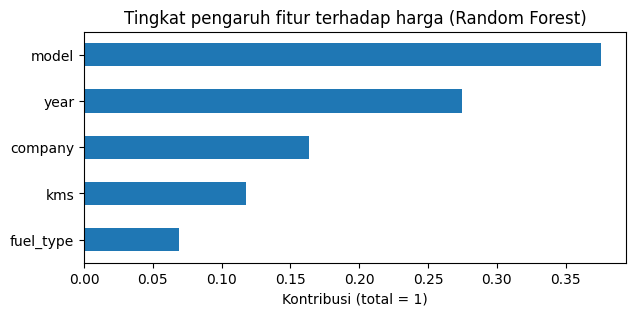

In [ ]:
nama_fitur_rf = model_rf.named_steps['preprocess'].get_feature_names_out()
pentingnya_rf = pd.Series(model_rf.named_steps['forest'].feature_importances_, index=nama_fitur_rf)

# Gabungkan hasil One-Hot (mis. company_Hyundai) kembali per kolom asal
def kolom_asal_rf(n):
    n = n.replace('kategori__', '').replace('remainder__', '')
    for k in FITUR_KATEGORI_RF:
        if n.startswith(k + '_'):
            return k
    return n

per_kolom_rf = pentingnya_rf.groupby(kolom_asal_rf).sum().sort_values()

per_kolom_rf.plot(kind='barh', figsize=(7, 3), title='Tingkat pengaruh fitur terhadap harga (Random Forest)')
plt.xlabel('Kontribusi (total = 1)')
plt.show()

## 5. Prediksi Harga dari Input User

Jalankan sel di bawah, lalu isi data mobil yang diminta. Program akan menampilkan **estimasi harga** beserta **rentang prediksi**. Karena Random Forest terdiri dari banyak pohon, rentang diambil dari sebaran prediksi tiap pohon (persentil 10 - 90) : makin sempit rentangnya, makin sepakat pohon-pohon tersebut.

Catatan :
- Harga pada dataset adalah **Rupee India (INR)**. Konversi ke Rupiah bersifat perkiraan, ubah `KURS_INR_KE_IDR` sesuai kurs terbaru.
- Jika model mobil yang diketik tidak ada di dataset, prediksi hanya memakai merk, tahun, jarak tempuh, dan bahan bakar sehingga akurasinya lebih rendah.

In [ ]:
KURS_INR_KE_IDR = 195   # perkiraan, sesuaikan dengan kurs terbaru

daftar_merk_rf = sorted(data_rf['company'].unique())
daftar_bbm_rf = sorted(data_rf['fuel_type'].unique())
tahun_min_rf, tahun_max_rf = int(data_rf['year'].min()), int(data_rf['year'].max())


def input_angka_rf(pesan, minimum, maksimum):
    while True:
        try:
            nilai = int(input(pesan).replace(',', '').replace('.', '').strip())
            if minimum <= nilai <= maksimum:
                return nilai
            print(f"  Masukkan angka antara {minimum} dan {maksimum}.")
        except ValueError:
            print("  Input harus berupa angka.")


def input_pilihan_rf(pesan, pilihan):
    peta = {p.lower(): p for p in pilihan}
    while True:
        jawab = input(pesan).strip().lower()
        if jawab in peta:
            return peta[jawab]
        print("  Pilihan tidak ditemukan, coba lagi.")


def prediksi_harga_rf(merk, nama_mobil, tahun, kms, bbm):
    model_mobil = ' '.join(nama_mobil.split()[:3])
    baris = pd.DataFrame([{
        'company': merk, 'model': model_mobil, 'fuel_type': bbm,
        'year': tahun, 'kms': kms
    }])
    harga = model_rf.predict(baris)[0]

    # Sebaran prediksi dari setiap pohon di dalam hutan
    data_angka = model_rf.named_steps['preprocess'].transform(baris)
    per_pohon = np.array([p.predict(data_angka)[0] for p in model_rf.named_steps['forest'].estimators_])
    rendah, tinggi = np.percentile(per_pohon, [10, 90])

    return harga, rendah, tinggi, model_mobil in set(data_rf['model'])


def jalankan_program_rf():
    print("=" * 55)
    print("   PREDIKSI HARGA MOBIL BEKAS (Random Forest)")
    print("=" * 55)
    print("Merk tersedia :", ', '.join(daftar_merk_rf))
    merk = input_pilihan_rf("Merk mobil              : ", daftar_merk_rf)

    contoh = data_rf.loc[data_rf['company'] == merk, 'model'].value_counts().head(8).index.tolist()
    print("Contoh model di dataset :", ', '.join(contoh))
    nama = input(f"Nama/model mobil (mis. {contoh[0]}) : ").strip()
    if not nama.lower().startswith(merk.lower()):
        nama = f"{merk} {nama}"   # lengkapi dengan merk agar sama dengan format dataset

    tahun = input_angka_rf(f"Tahun pembuatan ({tahun_min_rf}-{tahun_max_rf}) : ", tahun_min_rf, tahun_max_rf)
    kms = input_angka_rf("Jarak tempuh (km)         : ", 0, 1_000_000)
    print("Bahan bakar tersedia :", ', '.join(daftar_bbm_rf))
    bbm = input_pilihan_rf("Jenis bahan bakar        : ", daftar_bbm_rf)

    harga, rendah, tinggi, model_dikenal = prediksi_harga_rf(merk, nama, tahun, kms, bbm)

    print("\n" + "-" * 55)
    print(f"Mobil   : {nama} | {tahun} | {kms:,} km | {bbm}")
    print(f"Prediksi harga : Rp {harga * KURS_INR_KE_IDR:,.0f}  (INR {harga:,.0f})")
    print(f"Rentang prediksi antar pohon (P10 - P90) : INR {rendah:,.0f} - {tinggi:,.0f}")
    if not model_dikenal:
        print("Catatan : model mobil ini tidak ada di dataset, prediksi kurang akurat.")
    print("-" * 55)


jalankan_program_rf()

   PREDIKSI HARGA MOBIL BEKAS (Random Forest)
Merk tersedia : Audi, BMW, Chevrolet, Datsun, Fiat, Force, Ford, Hindustan, Honda, Hyundai, Jeep, Mahindra, Maruti, Mercedes, Mitsubishi, Nissan, Renault, Skoda, Tata, Toyota, Volkswagen
Merk mobil              : Maruti
Contoh model di dataset : Maruti Suzuki Swift, Maruti Suzuki Alto, Maruti Suzuki Wagon, Maruti Suzuki Ertiga, Maruti Suzuki Dzire, Maruti Suzuki Zen, Maruti Suzuki Omni, Maruti Suzuki Ritz
Nama/model mobil (mis. Maruti Suzuki Swift) : Maruti Suzuki Alto
Tahun pembuatan (1995-2019) : 2015
Jarak tempuh (km)         : 38.000
Bahan bakar tersedia : Diesel, LPG, Petrol
Jenis bahan bakar        : Petrol

-------------------------------------------------------
Mobil   : Maruti Suzuki Alto | 2015 | 38,000 km | Petrol
Prediksi harga : Rp 40,123,199  (INR 205,760)
Rentang prediksi antar pohon (P10 - P90) : INR 75,000 - 265,500
-------------------------------------------------------


## Kesimpulan Model Random Forest

- Random Forest dilatih dari data yang sudah dibersihkan (outlier dibuang, fitur `model` ditambahkan). Lihat hasil evaluasi di atas untuk R2 dan MAE pada data test (angka bisa berubah tergantung pembagian data).
- Merata-ratakan banyak pohon biasanya membuat prediksi lebih stabil, tetapi Random Forest tetap bisa overfitting. Cek selisih R2 training dan testing pada bagian analisis di atas.
- Seperti pada kesimpulan EDA, data ini terbatas (tidak ada fitur seperti kondisi mobil, tipe transmisi, atau kapasitas mesin), sehingga akurasi model punya batas.
- Kelemahan Random Forest : lebih lambat dilatih dan lebih sulit dijelaskan dibanding Decision Tree, karena tidak ada satu pohon yang bisa digambar sebagai alur keputusan.
- Hasil prediksi sebaiknya dipakai sebagai **perkiraan awal**, bukan harga pasti. Untuk memperbaiki : kumpulkan data lebih banyak, atau coba Gradient Boosting.